# HW2

In [7]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

## Problem 1

As shown from the simulation below, rolling seven is more probable than rolling snake eyes.

The probability ratio is

$$
\frac{P(7)}{P(2)} = \frac{6}{1} = 6.
$$

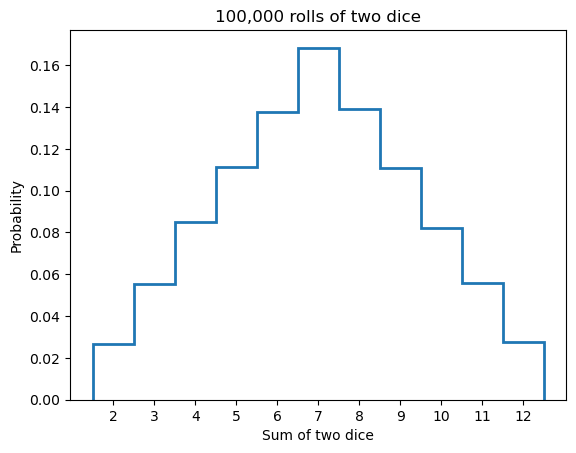

In [2]:
N = 100000
d1 = stats.randint.rvs(1, 7, size=N)
d2 = stats.randint.rvs(1, 7, size=N)
d = d1 + d2

fig, ax = plt.subplots()
ax.hist(
    d,
    bins=np.arange(1.5, 13.5, 1),
    histtype="step",
    linewidth=2,
    density=True,
)
ax.set(
    xlabel="Sum of two dice",
    ylabel="Probability",
    title=f"{N:,} rolls of two dice",
    xticks=range(2, 13),
)
plt.show()

## Problem 2

### Analytical Solution: Convolution of Two Dice

Let $X$ and $Y$ be two independent random variables representing the outcomes of two fair six-sided dice.

Their probability mass functions are

$$
p_X(x)=p_Y(x)=
\begin{cases}
\frac{1}{6}, & x=1,2,\ldots,6,\\
0, & \text{otherwise}.
\end{cases}
$$

Define the sum $Z=X+Y$. By discrete convolution,

$$
p_Z(z)=(p_X*p_Y)(z)
=\sum_{x=-\infty}^{\infty}p_X(x)p_Y(z-x).
$$

Therefore,

$$
\boxed{
p_Z(z)=
\begin{cases}
\frac{z-1}{36}, & 2\le z\le 7,\\[4pt]
\frac{13-z}{36}, & 8\le z\le 12,\\[4pt]
0, & \text{otherwise}.
\end{cases}
}
$$

Equivalently,

$$
\boxed{
p_Z(z)=\frac{6-|z-7|}{36},
\qquad z=2,3,\ldots,12.
}
$$

Finally, we verify normalization:

$$
\sum_{z=2}^{12}p_Z(z)
=\frac{1+2+3+4+5+6+5+4+3+2+1}{36}
=\frac{36}{36}=1.
$$

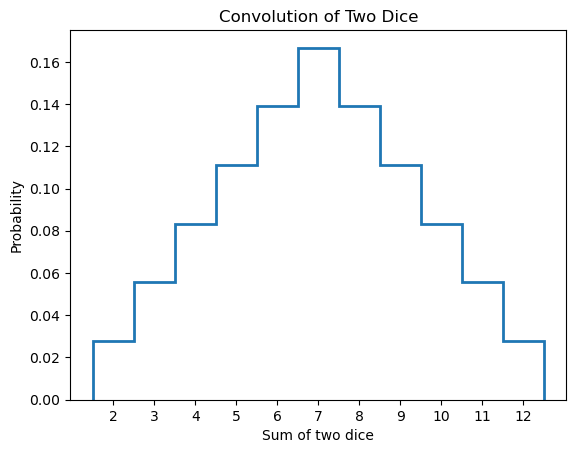

In [3]:
p = np.ones(6) / 6
p_sum = np.convolve(p, p, mode = 'full')
x_sum = np.arange(2, 13)

fig, ax = plt.subplots()

ax.stairs(
    p_sum,
    edges=np.arange(1.5, 13.5, 1),
    linewidth=2
)

ax.set(
    xlabel="Sum of two dice",
    ylabel="Probability",
    title="Convolution of Two Dice",
    xticks=x_sum
)

plt.show()

## Problem 3

### Mean and variance of two dice distribution

By the definition of mean and variance, we have:

In [4]:
mean = np.sum(x_sum * p_sum)
variance = np.sum((x_sum - mean)**2 * p_sum)

print("Mean:", mean)
print("Variance:", variance)

Mean: 6.999999999999998
Variance: 5.833333333333333


## Problem 4

### Distribution of the average of 10 dice

Convolve the distribution 9 times:

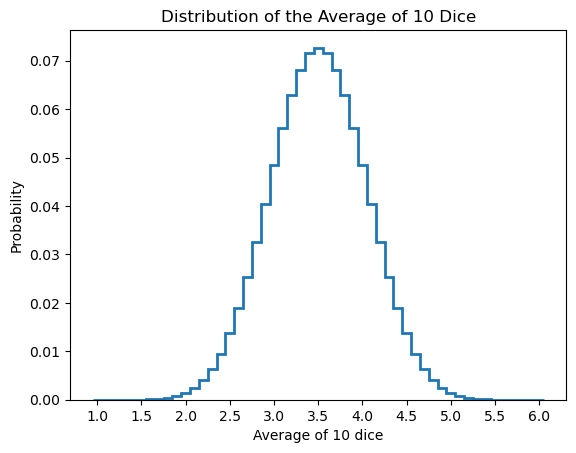

In [5]:
p = np.ones(6) / 6
p_10 = p.copy()
x_10 = np.arange(10, 61)
x_avg = x_10 / 10

for _ in range(9):
    p_10 = np.convolve(p_10, p, mode = 'full')

fig, ax = plt.subplots()

ax.stairs(
    p_10,
    edges=np.arange(9.5, 61.5) / 10,
    linewidth=2
)

ax.set(
    xlabel="Average of 10 dice",
    ylabel="Probability",
    title="Distribution of the Average of 10 Dice",
    xticks=np.arange(1, 6.1, 0.5)
)

plt.show()

As we can see from the distribution above, the average of 10 dice already resembles a Gaussian distribution, although it is not exactly Gaussian.

As the number of dice increases, the appropriately standardized distribution approaches a Gaussian distribution. This is a consequence of the **Central Limit Theorem (CLT)**, which states:

Let $X_1,X_2,\ldots,X_n$ be independent and identically distributed random variables with finite mean $\mu$ and variance $\sigma^2$. Define their sample mean as

$$
\bar X_n=\frac{1}{n}\sum_{i=1}^{n}X_i.
$$

Then, as $n\to\infty$,

$$
\boxed{
\frac{\bar X_n-\mu}{\sigma/\sqrt{n}}
\xrightarrow{d}\mathcal N(0,1)
}
$$


Equivalently, for sufficiently large $n$,

$$
\boxed{
\bar X_n\approx\mathcal N\left(\mu,\frac{\sigma^2}{n}\right).
}
$$

For a fair six-sided die,

$$
\mu=\frac72,\qquad \sigma^2=\frac{35}{12}.
$$

Therefore, the average of $n$ independent dice approximately follows

$$
\boxed{
\bar X_n\approx\mathcal N\left(\frac72,\frac{35}{12n}\right).
}
$$

## Problem 5

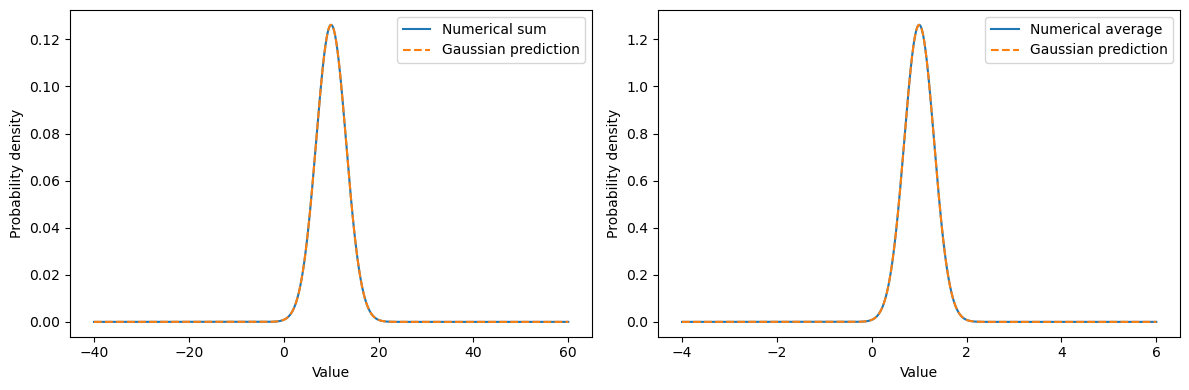

Sum: mean = 10.000000, SD = 3.162255
Average: mean = 1.000000, SD = 0.316225


In [10]:
mu = 1
sigma = 1
N = 10

x = np.linspace(mu - 5 * sigma, mu + 5 * sigma, 1000)
dx = x[1] - x[0]

f = stats.norm.pdf(x, loc = mu, scale = sigma)
p = f * dx
p /= p.sum()

p_sum = p.copy()
for _ in range(N - 1):
    p_sum = np.convolve(p_sum, p, mode = 'full')

x_sum = N * x[0] + dx * np.arange(len(p_sum))
x_avg = x_sum / 10
f_sum = p_sum / dx
f_avg = N * f_sum


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x_sum, f_sum, label="Numerical sum")
axes[0].plot(
    x_sum,
    stats.norm.pdf(x_sum, loc=N*mu, scale=np.sqrt(N)*sigma),
    "--", label="Gaussian prediction"
)

axes[1].plot(x_avg, f_avg, label="Numerical average")
axes[1].plot(
    x_avg,
    stats.norm.pdf(x_avg, loc=mu, scale=sigma/np.sqrt(N)),
    "--", label="Gaussian prediction"
)

for ax in axes:
    ax.set(xlabel="Value", ylabel="Probability density")
    ax.legend()

plt.tight_layout()
plt.show()

for name, values in [("Sum", x_sum), ("Average", x_avg)]:
    mean = np.sum(values * p_sum)
    sd = np.sqrt(np.sum((values - mean)**2 * p_sum))
    print(f"{name}: mean = {mean:.6f}, SD = {sd:.6f}")

For $N$ independent Gaussian measurements, each with standard deviation $\sigma$, the standard deviation of their sum is

$$
\sigma_{\mathrm{sum}}=\sqrt{N}\,\sigma.
$$

Their average is the sum divided by $N$, so its standard deviation is

$$
\sigma_{\mathrm{avg}}
=\frac{\sigma_{\mathrm{sum}}}{N}
=\frac{\sigma}{\sqrt{N}}.
$$

Thus, adding measurements increases the absolute uncertainty of the sum, while averaging reduces the uncertainty of the estimated mean.

For a steady signal with independent, zero-mean Gaussian noise, the accumulated signal grows in proportion to $N$, while the noise standard deviation grows only as $\sqrt{N}$. The signal-to-noise ratio therefore improves as $\sqrt{N}$. At a fixed sampling interval, $N$ is proportional to the integration time $T$, so the signal-to-noise ratio grows as $\sqrt{T}$ and the uncertainty of the average decreases as $1/\sqrt{T}$. For example, integrating four times longer halves the uncertainty of the average. This assumes the signal stays steady and the noise samples are independent; a shared systematic error does not average away.